Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Load the movies dataset
automobiles_df = pd.read_csv('automobile.txt')

# The below shows the columns before removed below - a quick sense check.
#automobiles_df.info

### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [3]:
# Code here
missing_values_count = automobiles_df.isnull().sum()
missing_values_count

missing = (automobiles_df == '?').sum()
missing

clean_automobiles_df = automobiles_df.drop(['normalized-losses', 'symboling'],axis=1)
clean_automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

In [4]:
# Code here
duplicates_removed_automobiles_df = clean_automobiles_df.drop_duplicates()
duplicates_removed_automobiles_df.head(5)

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [5]:
# Code here
temp_df = duplicates_removed_automobiles_df.dropna()
temp_df.head(5)

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [6]:
# Code here

type_df = temp_df.dtypes == "float64"

temp_df = temp_df.astype({
    col: 'int64'
    for col in temp_df.columns[type_df]
})

print(temp_df.dtypes)

make                 object
fuel-type            object
aspiration           object
num-of-doors         object
body-style           object
drive-wheels         object
engine-location      object
wheel-base            int64
length                int64
width                 int64
height                int64
curb-weight           int64
engine-type          object
num-of-cylinders     object
engine-size           int64
fuel-system          object
bore                 object
stroke               object
compression-ratio     int64
horsepower           object
peak-rpm             object
city-mpg              int64
highway-mpg           int64
price                object
dtype: object


### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [7]:
# Create a dataframe with all the cars in the "hatchback' category
hatchback_cars = temp_df[temp_df['body-style'].isin(['hatchback'])]
hatchback_cars.head(5)

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94,171,65,...,152,mpfi,2.68,3.47,9,154,5000,19,26,16500
9,audi,gas,turbo,two,hatchback,4wd,front,99,178,67,...,131,mpfi,3.13,3.40,7,160,5500,16,22,?
18,chevrolet,gas,std,two,hatchback,fwd,front,88,141,60,...,61,2bbl,2.91,3.03,9,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94,155,63,...,90,2bbl,3.03,3.11,9,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93,157,63,...,90,2bbl,2.97,3.23,9,68,5500,37,41,5572


### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [8]:
# Code here
# Replace '?' with NaN
temp_df['price'] = temp_df['price'].replace('?', np.nan)

# Convert price to numbers
temp_df['price'] = pd.to_numeric(temp_df['price'])

expensive_cars = temp_df.sort_values('price', ascending=False).head(5)
cheapest_cars = temp_df.sort_values('price', ascending=True).head(5)

# expensive_cars has ? so some are missing values which I sorted above
# expensive_cars have low city and highway mpg compared to cheapest_cars which are more fuel efficient

print(expensive_cars[['make', 'price', 'city-mpg', 'highway-mpg']])
print(cheapest_cars[['make', 'price', 'city-mpg', 'highway-mpg']])

              make    price  city-mpg  highway-mpg
74   mercedes-benz  45400.0        14           16
16             bmw  41315.0        16           22
73   mercedes-benz  40960.0        14           16
128        porsche  37028.0        17           25
17             bmw  36880.0        15           20
           make   price  city-mpg  highway-mpg
138      subaru  5118.0        31           36
18    chevrolet  5151.0        47           53
50        mazda  5195.0        30           31
150      toyota  5348.0        35           39
76   mitsubishi  5389.0        37           41


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

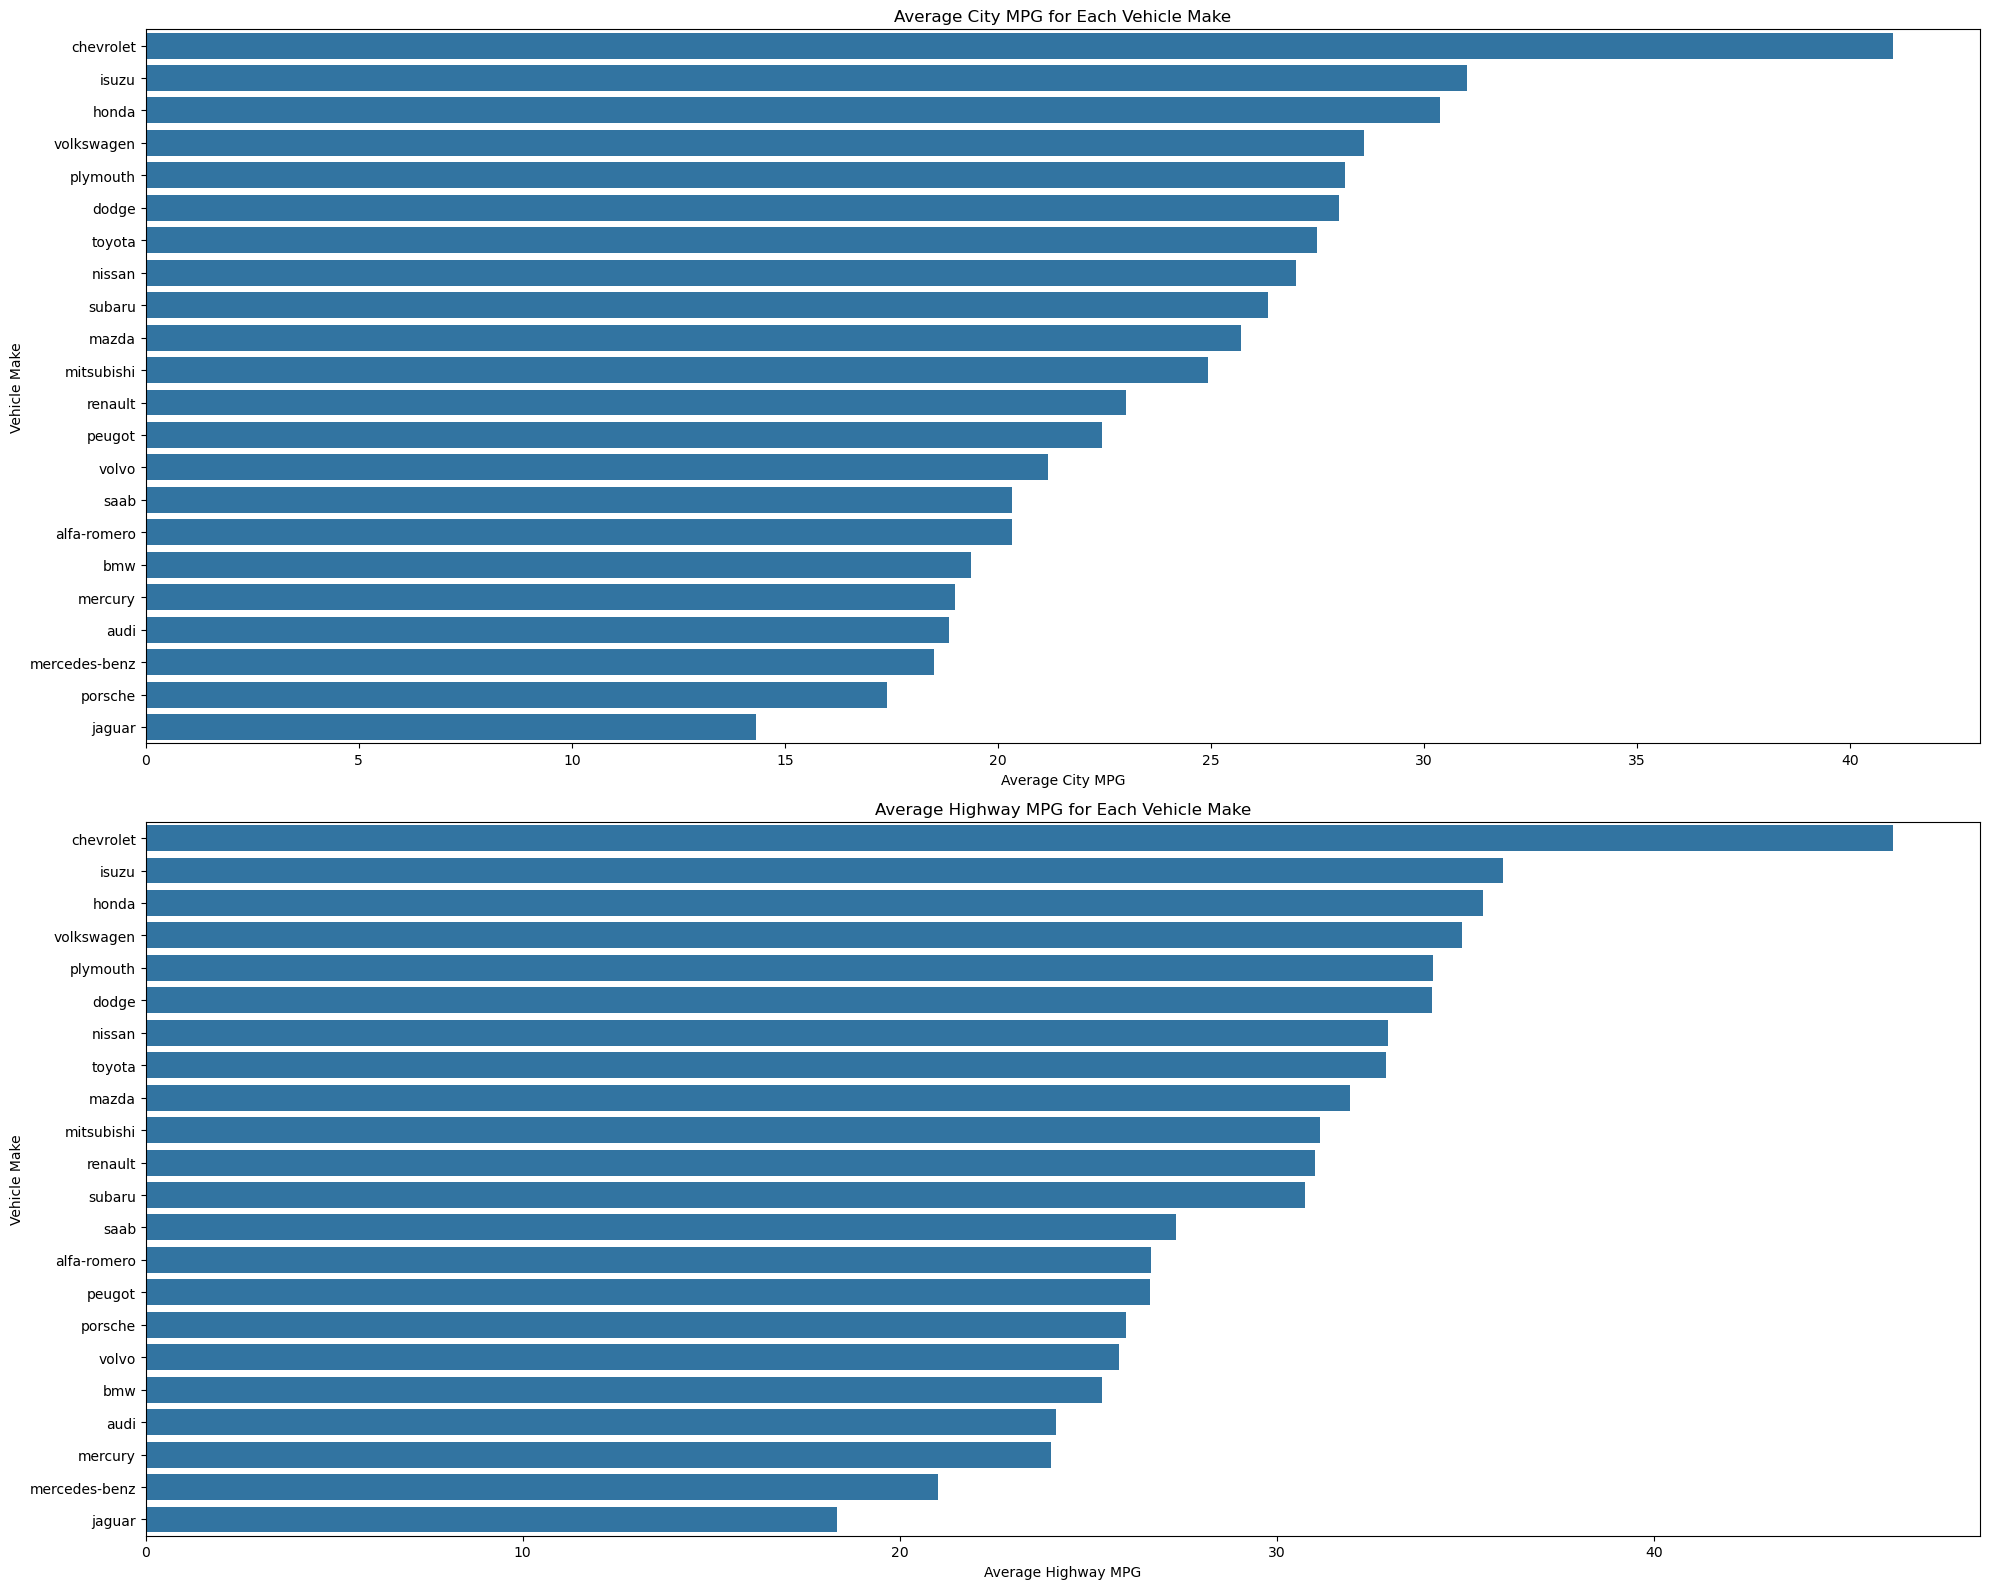

In [9]:
# Code here

average_city_mpg = temp_df.groupby('make')['city-mpg'].mean()
average_highway_mpg = temp_df.groupby('make')['highway-mpg'].mean()

fig, ax = plt.subplots(2, 1, figsize=(20, 16))
sns.barplot(x=average_city_mpg.values,
            y=average_city_mpg.index,
            order=average_city_mpg.sort_values(ascending=False).index,
           ax=ax[0])
ax[0].set_title("Average City MPG for Each Vehicle Make")
ax[0].set_xlabel("Average City MPG")
ax[0].set_ylabel("Vehicle Make")


sns.barplot(x=average_highway_mpg.values,
            y=average_highway_mpg.index,
            order=average_highway_mpg.sort_values(ascending=False).index,
           ax=ax[1])
ax[1].set_title("Average Highway MPG for Each Vehicle Make")
ax[1].set_xlabel("Average Highway MPG")
ax[1].set_ylabel("Vehicle Make")

plt.tight_layout()
plt.show()

# The manufacturer with the highest average city MPG and average highway MPG is Chevrolet


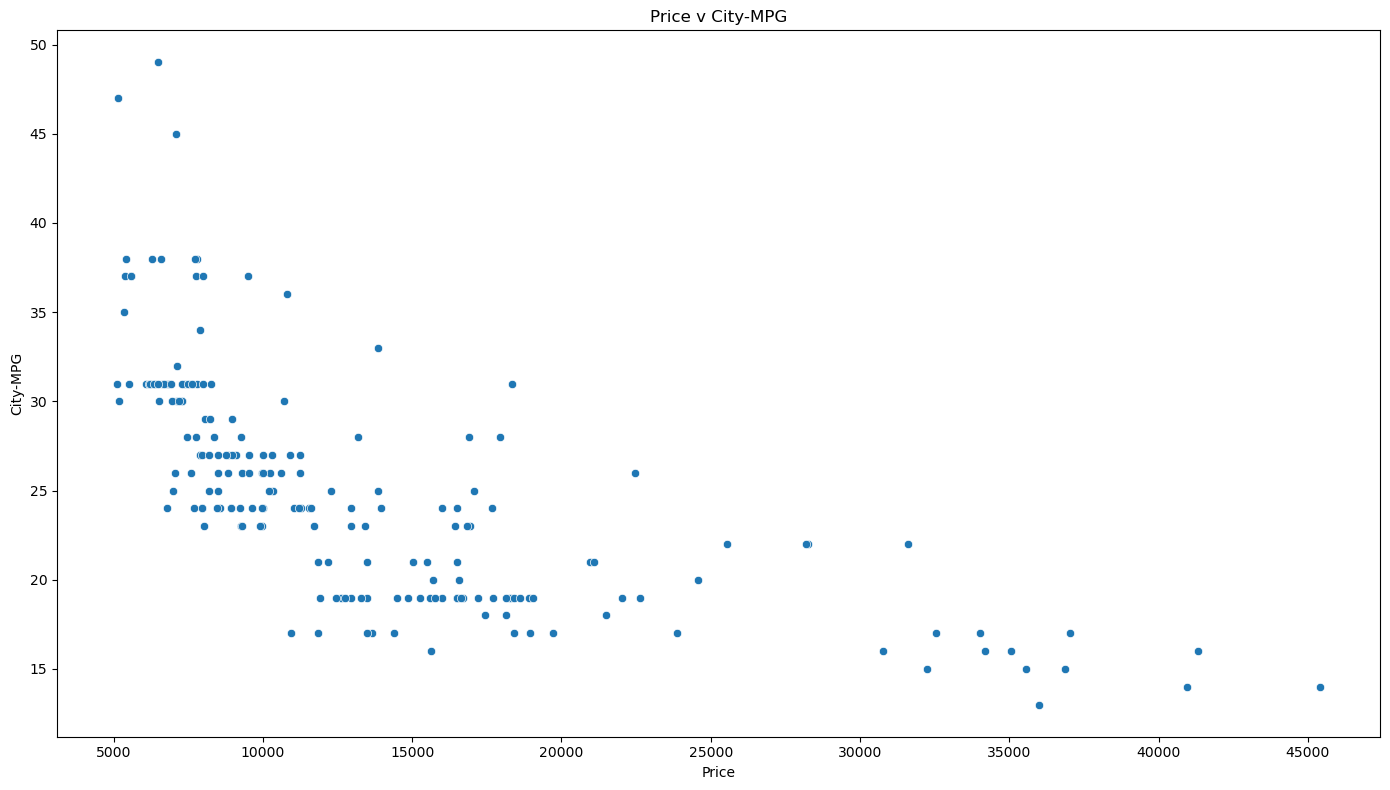

In [10]:
# Create a single figure with 1 subplots
fig, ax = plt.subplots(1,1, figsize=(14, 8))

# Plot: Earnings by Sport
sns.scatterplot(
    data=temp_df,
    x= 'price',
    y='city-mpg',
    ax=ax
)

# Add title and labels
ax.set_title("Price v City-MPG")
ax.set_xlabel("Price")
ax.set_ylabel("City-MPG")


# Adjust layout
plt.tight_layout()

# Display the plot
plt.show()

# This shows a general trend of price and city MPG, as price increases a decrease in city MPG is seen. So more expensive cars use more fuel per mile generally. 

#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [11]:
# Code here

engine_size = temp_df.sort_values('engine-size', ascending=False)

# Either way can be used
engine_max = temp_df['engine-size'].max()

engine_size[['make', 'engine-size']].head(5)

# The vehicle with the largest engine capacity is Jaguar

,make,engine-size
49,jaguar,326
73,mercedes-benz,308
74,mercedes-benz,304
48,jaguar,258
47,jaguar,258


#### Which vehicle manufacturer has the most car models in the dataset

In [12]:
# Code here

# Count the number of car models for each manufacturer
most_make = temp_df.groupby('make').size()

# Display manufacturers in descending order by number of models
top_manufacturer = most_make.idxmax()
number_of_models = most_make.max()

print(f"The manufacturer with the most models is {top_manufacturer}, with {number_of_models} models.")

The manufacturer with the most models is toyota, with 32 models.
